In [2]:
from presyo_ph.medallion.gold import load_gold_table
from presyo_ph.spark import get_spark_session

from presyo_ph.ml import (
    ForecastConfig,
    prepare_time_series,
)

import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
import pandas as pd

In [5]:
spark = get_spark_session()
gold_df = load_gold_table(spark, "national_monthly_prices")
rice_df = (
    gold_df
    .filter("commodity = 'rice'")
    .select("price_date", "avg_price")
    .toPandas()
)

rice_df

Gold table loaded: national_monthly_prices (local)


,price_date,avg_price
0,2007-01-01,21.402857
1,2007-02-01,21.645714
2,2007-03-01,22.217143
3,2007-04-01,22.410714
4,2007-05-01,22.712857
...,...,...
220,2025-05-01,42.893494
221,2025-06-01,42.061084
222,2025-07-01,40.849518
223,2025-08-01,39.862289


In [7]:
config = ForecastConfig(
    date_col="price_date",
    target_col="avg_price",
    horizon=12,
    test_size=12,
)

rice_series = prepare_time_series(
    rice_df,
    date_col=config.date_col,
    target_col=config.target_col,
)

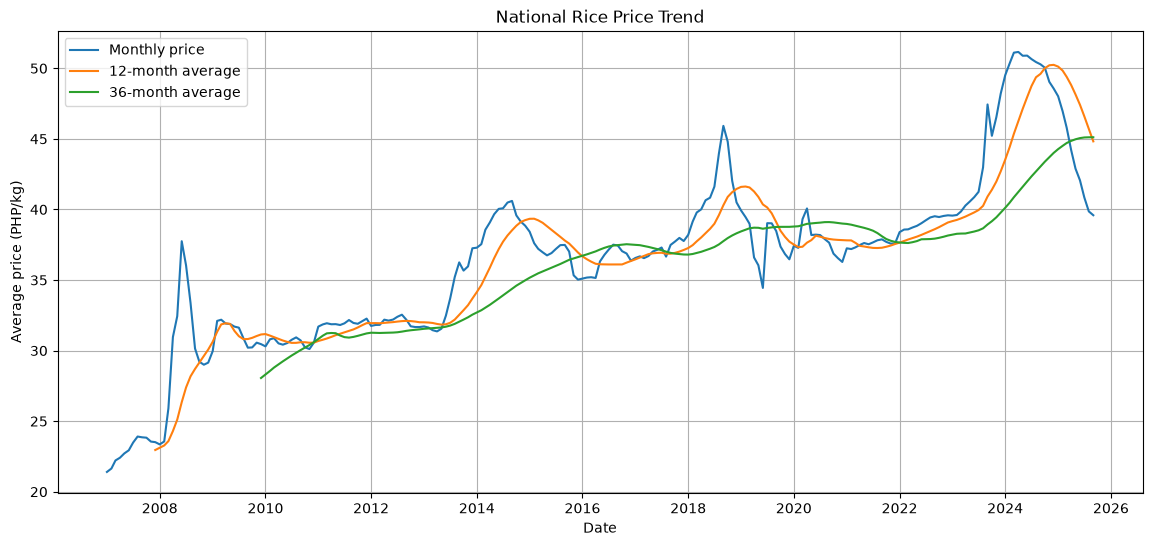

In [8]:
rolling_12 = rice_series.rolling(12).mean()
rolling_36 = rice_series.rolling(36).mean()

plt.figure(figsize=(14, 6))

plt.plot(rice_series, label="Monthly price")
plt.plot(rolling_12, label="12-month average")
plt.plot(rolling_36, label="36-month average")

plt.title("National Rice Price Trend")
plt.xlabel("Date")
plt.ylabel("Average price (PHP/kg)")
plt.legend()
plt.grid(True)
plt.show()

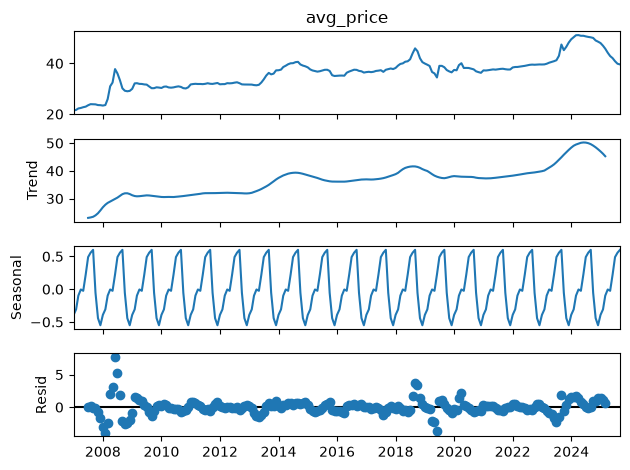

In [9]:
decomposition = seasonal_decompose(
    rice_series,
    model="additive",
    period=12,
)

decomposition.plot()
plt.show()

In [10]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(rice_series.dropna(), result_object=False)

print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Critical Values:", result[4])

ADF Statistic: -2.4853409064968037
p-value: 0.11908190277364944
Critical Values: {'1%': np.float64(-3.4602906385073884), '5%': np.float64(-2.874708679520702), '10%': np.float64(-2.573788599127782)}


In [11]:
rice_diff = rice_series.diff().dropna()

result_diff = adfuller(rice_diff, result_object=False)

print("ADF Statistic:", result_diff[0])
print("p-value:", result_diff[1])

ADF Statistic: -8.161697505838365
p-value: 9.107136344692673e-13


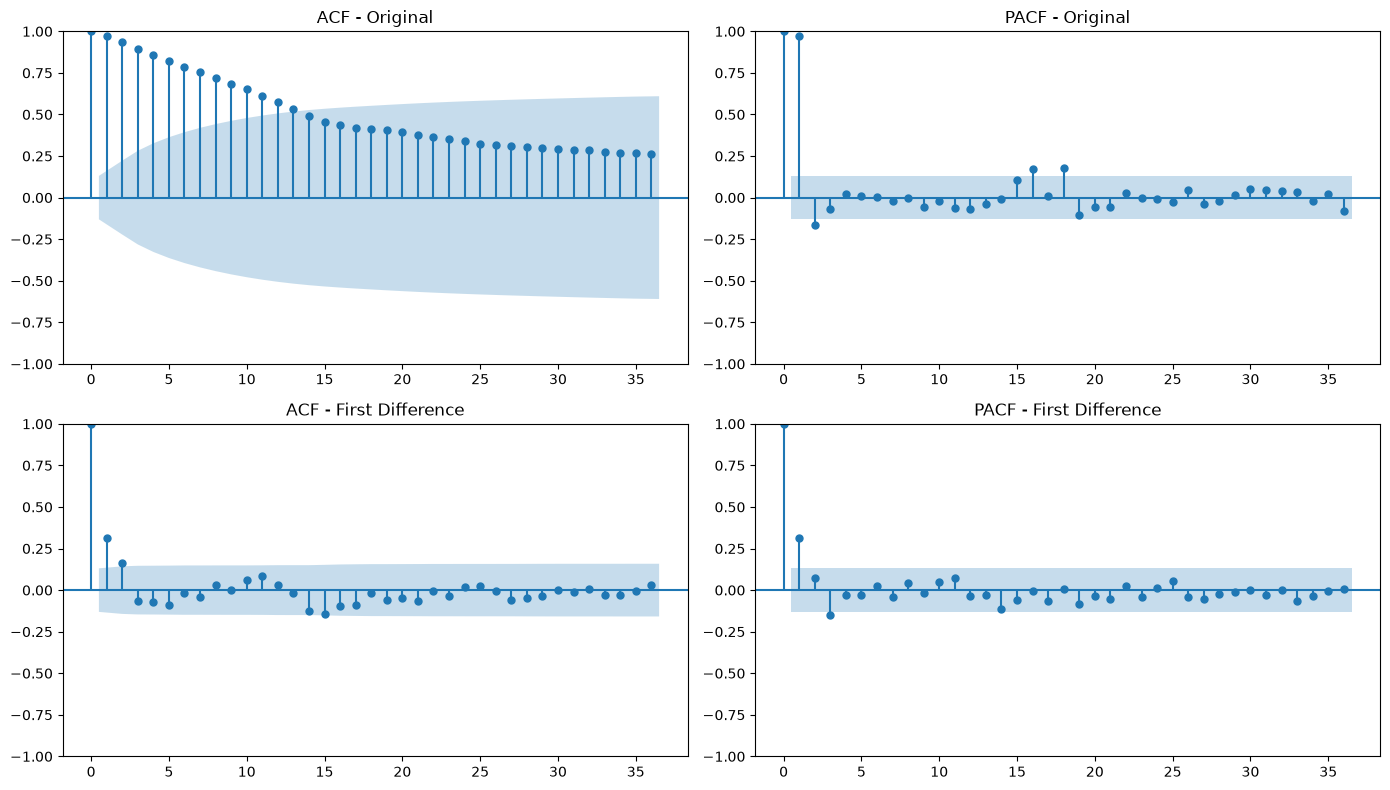

In [12]:
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf,
)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_acf(rice_series, lags=36, ax=axes[0, 0])
plot_pacf(rice_series, lags=36, ax=axes[0, 1])

plot_acf(rice_diff, lags=36, ax=axes[1, 0])
plot_pacf(rice_diff, lags=36, ax=axes[1, 1])

axes[0, 0].set_title("ACF - Original")
axes[0, 1].set_title("PACF - Original")
axes[1, 0].set_title("ACF - First Difference")
axes[1, 1].set_title("PACF - First Difference")

plt.tight_layout()
plt.show()

In [13]:
rolling_mean = rice_series.rolling(12).mean()
rolling_std = rice_series.rolling(12).std()

z_scores = (
    (rice_series - rolling_mean)
    / rolling_std
)

outliers = rice_series[
    z_scores.abs() > 3
]

display(outliers.to_frame("price"))

,price
price_date,


In [14]:
from statsmodels.tsa.arima.model import ARIMA

candidates = {
    "ARIMA(1,1,1)": (1, 1, 1),
    "ARIMA(1,1,2)": (1, 1, 2),
    "ARIMA(3,1,1)": (3, 1, 1),
}

results = []

for name, order in candidates.items():
    model = ARIMA(rice_series, order=order)
    fitted = model.fit()

    results.append({
        "model": name,
        "aic": fitted.aic,
        "bic": fitted.bic,
    })

model_comparison = (
    pd.DataFrame(results)
    .sort_values("aic")
    .reset_index(drop=True)
)

display(model_comparison)

,model,aic,bic
0,"ARIMA(1,1,2)",619.615649,633.262233
1,"ARIMA(3,1,1)",620.333484,637.391715
2,"ARIMA(1,1,1)",621.978580,632.213518


In [15]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

tscv = TimeSeriesSplit(n_splits=3, test_size=12)

results = []

for model_name, order in candidates.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(rice_series), start=1):
        train = rice_series.iloc[train_idx]
        test = rice_series.iloc[test_idx]

        model = ARIMA(train, order=order)
        fitted = model.fit()

        predictions = fitted.forecast(steps=len(test))

        mae = mean_absolute_error(test, predictions)
        rmse = np.sqrt(mean_squared_error(test, predictions))

        smape = (
            np.abs(test - predictions)
            / ((np.abs(test) + np.abs(predictions)) / 2)
        ).replace([np.inf, -np.inf], np.nan).dropna().mean() * 100

        results.append({
            "model": model_name,
            "fold": fold,
            "mae": mae,
            "rmse": rmse,
            "smape": smape,
        })

fold_results = pd.DataFrame(results)

display(fold_results)

,model,fold,mae,rmse,smape
0,"ARIMA(1,1,1)",1,1.368522,2.577382,3.263057
1,"ARIMA(1,1,1)",2,1.155527,1.635249,2.368575
2,"ARIMA(1,1,1)",3,5.384006,6.465998,11.633408
3,"ARIMA(1,1,2)",1,1.384056,2.588706,3.302279
4,"ARIMA(1,1,2)",2,1.190655,1.794282,2.439525
5,"ARIMA(1,1,2)",3,5.407623,6.488088,11.680168
6,"ARIMA(3,1,1)",1,1.539442,2.684330,3.695698
7,"ARIMA(3,1,1)",2,2.766743,2.907702,5.663851
8,"ARIMA(3,1,1)",3,5.516631,6.592100,11.895646


In [16]:
summary = (
    fold_results
    .groupby("model")
    .agg({
        "mae": ["mean", "std"],
        "rmse": ["mean", "std"],
        "smape": ["mean", "std"],
    })
    .round(4)
)

display(summary)

mae            rmse           smape        
                mean     std    mean     std    mean     std
model                                                       
ARIMA(1,1,1)  2.6360  2.3822  3.5595  2.5608  5.7550  5.1104
ARIMA(1,1,2)  2.6608  2.3808  3.6237  2.5122  5.8073  5.1043
ARIMA(3,1,1)  3.2743  2.0366  4.0614  2.1945  7.0851  4.2807

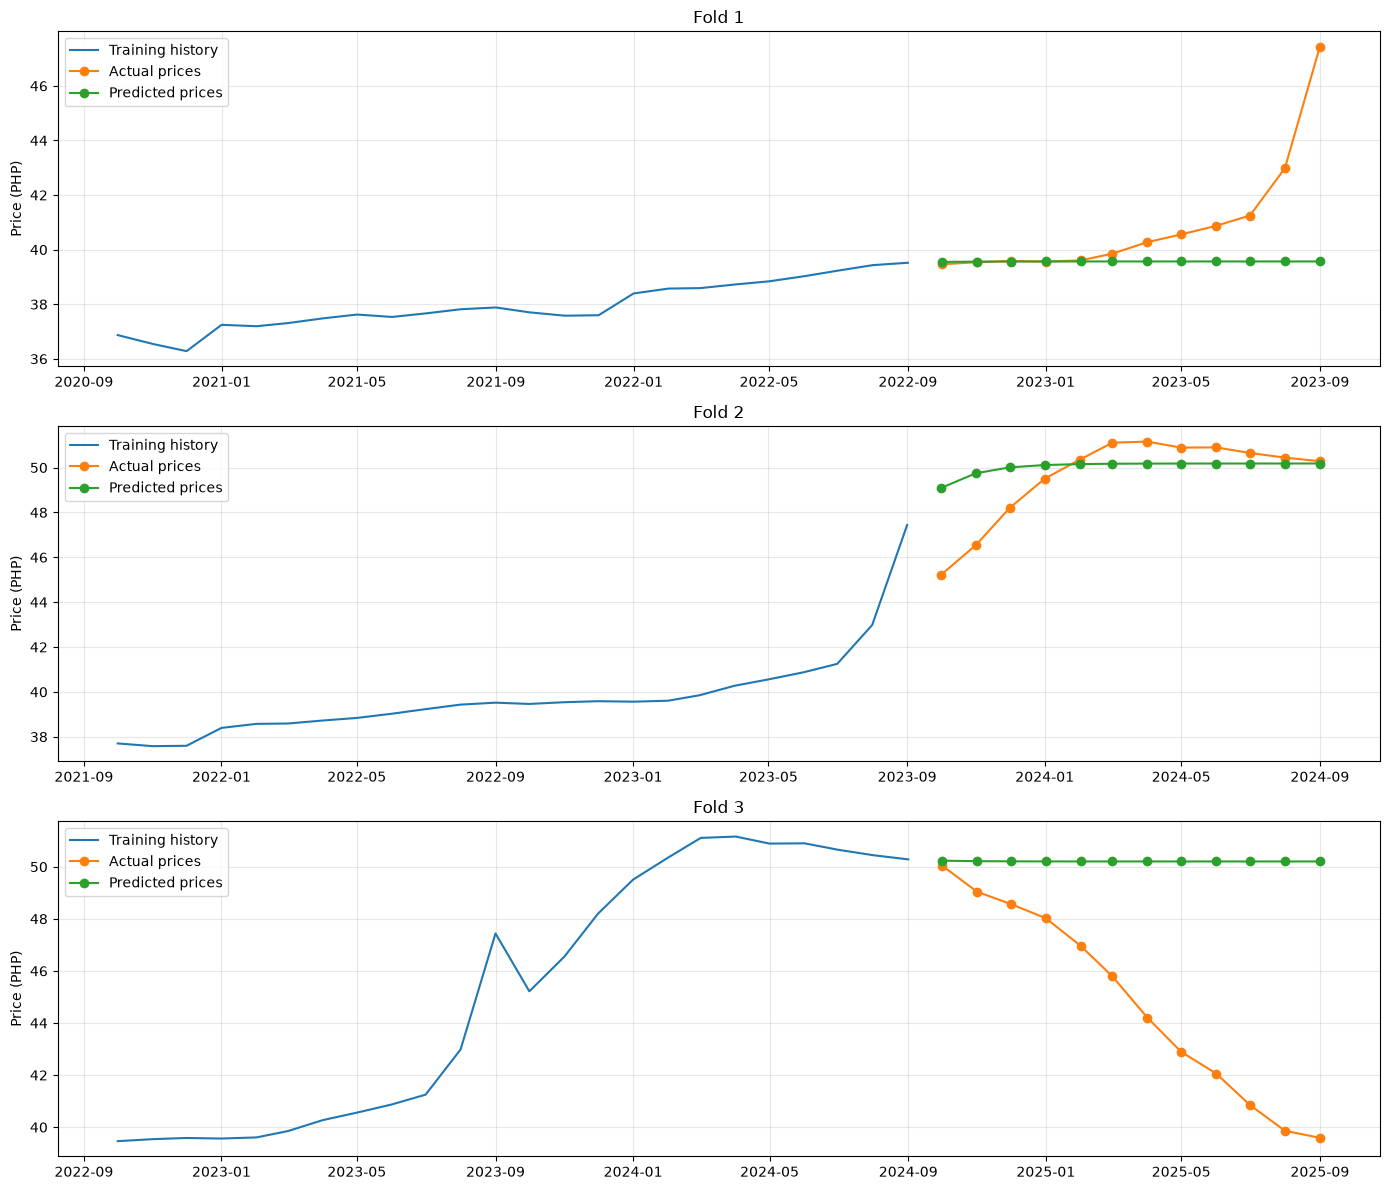

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for fold, (train_idx, test_idx) in enumerate(tscv.split(rice_series)):
    train = rice_series.iloc[train_idx]
    test = rice_series.iloc[test_idx]

    model = ARIMA(train, order=(1, 1, 1))
    fitted = model.fit()

    predictions = fitted.forecast(steps=len(test))

    axes[fold].plot(train.index[-24:], train.iloc[-24:],
                    label="Training history")
    axes[fold].plot(test.index, test,
                    label="Actual prices", marker="o")
    axes[fold].plot(predictions.index, predictions,
                    label="Predicted prices", marker="o")

    axes[fold].set_title(f"Fold {fold + 1}")
    axes[fold].set_ylabel("Price (PHP)")
    axes[fold].legend()
    axes[fold].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
results = []

for fold, (train_idx, test_idx) in enumerate(tscv.split(rice_series), start=1):
    train = rice_series.iloc[train_idx]
    test = rice_series.iloc[test_idx]

    # ARIMA
    fitted = ARIMA(train, order=(1, 1, 1)).fit()
    arima_pred = fitted.forecast(steps=len(test))

    # Naive baseline
    naive_pred = pd.Series(
        train.iloc[-1],
        index=test.index
    )

    for model_name, predictions in [
        ("ARIMA(1,1,1)", arima_pred),
        ("Naive", naive_pred),
    ]:
        results.append({
            "model": model_name,
            "fold": fold,
            "mae": mean_absolute_error(test, predictions),
            "rmse": np.sqrt(mean_squared_error(test, predictions)),
            "smape": (
                np.abs(test - predictions)
                / ((np.abs(test) + np.abs(predictions)) / 2)
            ).mean() * 100,
        })

comparison = pd.DataFrame(results)

display(
    comparison.groupby("model")[
        ["mae", "rmse", "smape"]
    ].mean().round(4)
)

,mae,rmse,smape
model,,,
"ARIMA(1,1,1)",2.6360,3.5595,5.7550
Naive,3.1832,3.9960,6.8815


In [23]:
display(
    comparison
    .pivot(index="fold", columns="model", values="mae")
    .round(4)
)

model,"ARIMA(1,1,1)",Naive
fold,,
1,1.3685,1.4048
2,1.1555,2.6848
3,5.3840,5.4600


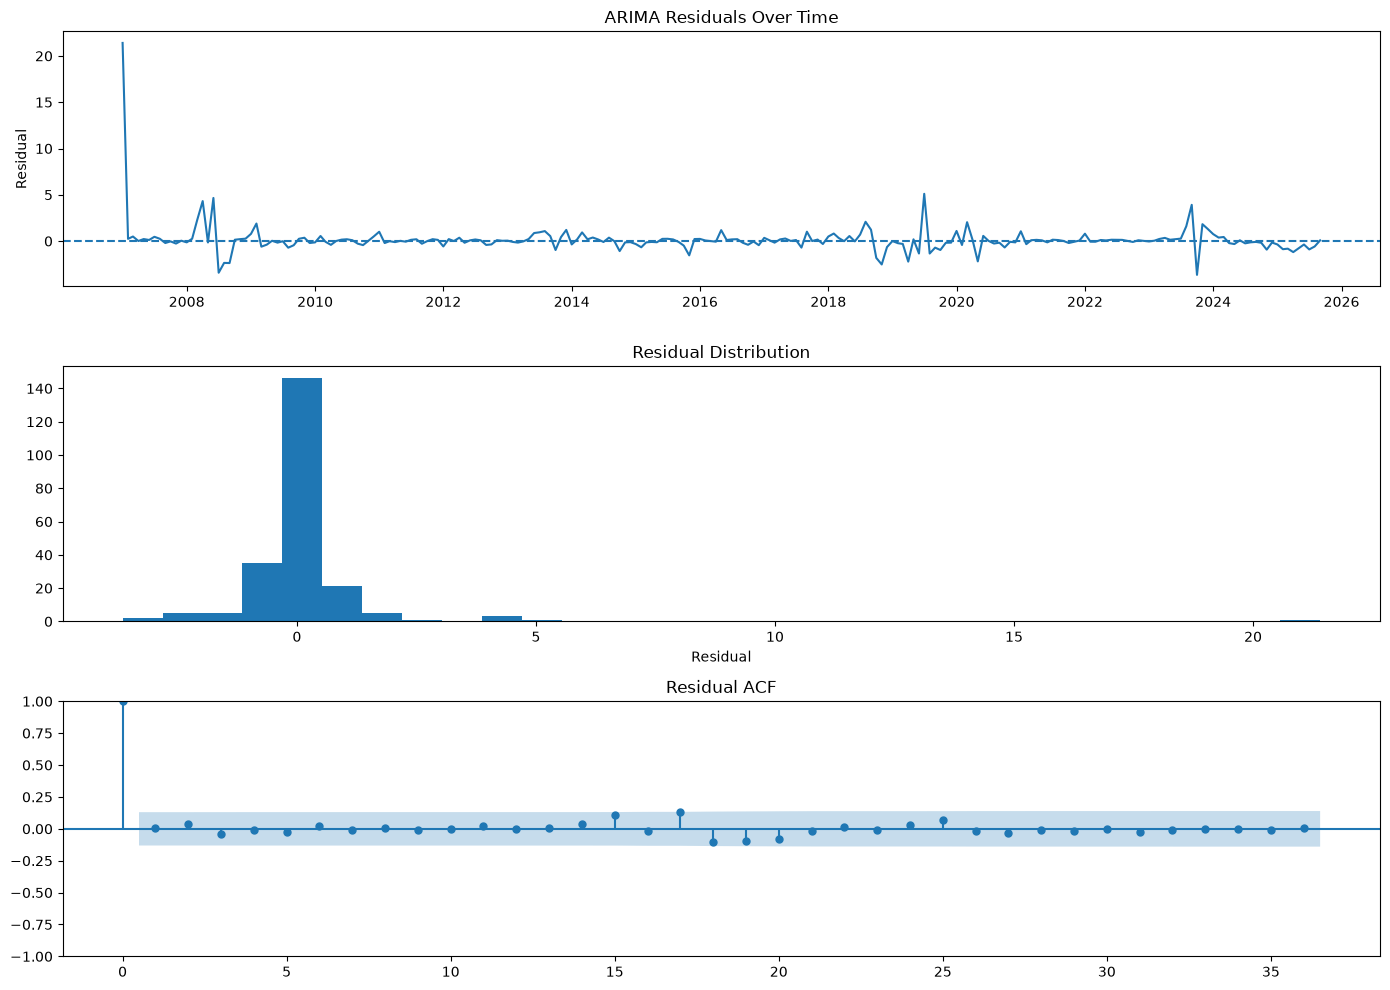

In [24]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

model = ARIMA(rice_series, order=(1, 1, 1))
fitted = model.fit()

residuals = fitted.resid.dropna()

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Residuals over time
axes[0].plot(residuals)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("ARIMA Residuals Over Time")
axes[0].set_ylabel("Residual")

# Residual distribution
axes[1].hist(residuals, bins=30)
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")

# Residual autocorrelation
plot_acf(residuals, lags=36, ax=axes[2])
axes[2].set_title("Residual ACF")

plt.tight_layout()
plt.show()

In [25]:
ljung_box = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    return_df=True
)

display(ljung_box)

,lb_stat,lb_pvalue
12,1.135367,0.999971
24,15.306702,0.911463


In [26]:
ljung_box = acorr_ljungbox(
    residuals,
    lags=[12, 24],
    model_df=2,
    return_df=True
)

display(ljung_box)

,lb_stat,lb_pvalue
12,1.135367,0.999693
24,15.306702,0.848743


In [27]:
model = ARIMA(rice_series, order=(1, 1, 1))
fitted = model.fit()

forecast_result = fitted.get_forecast(steps=12)

forecast_df = forecast_result.summary_frame(
    alpha=0.05
)

display(forecast_df)

avg_price,mean,mean_se,mean_ci_lower,mean_ci_upper
2025-10-01,39.464999,0.956729,37.589844,41.340154
2025-11-01,39.410782,1.572362,36.329008,42.492555
2025-12-01,39.387512,2.087263,35.296551,43.478474
2026-01-01,39.377526,2.528059,34.422622,44.332430
2026-02-01,39.373240,2.914046,33.661815,45.084664
2026-03-01,39.371400,3.258983,32.983912,45.758889
2026-04-01,39.370611,3.572486,32.368666,46.372556
2026-05-01,39.370272,3.861305,31.802252,46.938291
2026-06-01,39.370126,4.130253,31.274980,47.465273
2026-07-01,39.370064,4.382839,30.779857,47.960271


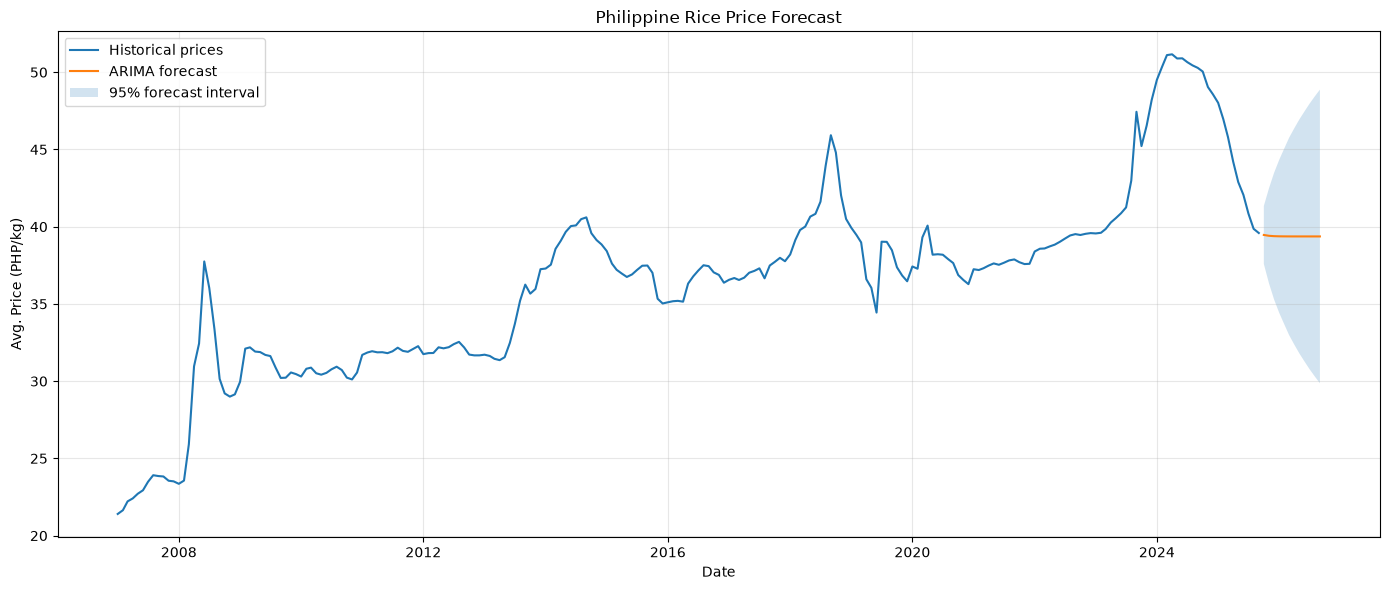

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    rice_series.index,
    rice_series,
    label="Historical prices"
)

plt.plot(
    forecast_df.index,
    forecast_df["mean"],
    label="ARIMA forecast"
)

plt.fill_between(
    forecast_df.index,
    forecast_df["mean_ci_lower"],
    forecast_df["mean_ci_upper"],
    alpha=0.2,
    label="95% forecast interval"
)

plt.title("Philippine Rice Price Forecast")
plt.xlabel("Date")
plt.ylabel("Avg. Price (PHP/kg)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()